Experiment: K-Means Clustering using Elbow Method and Silhouette Score

Aim: To perform clustering using K-Means and find the optimal number of clusters using the Elbow Method and the Silhouette Score.

Theory:
K-Means is an unsupervised learning algorithm. It divides the data into K groups (clusters) so that points in the same cluster are close to each other. The steps are:
1. Choose the number of clusters K.
2. Pick K random points as the initial centroids.
3. Assign every data point to its nearest centroid.
4. Recalculate each centroid as the mean of the points assigned to it.
5. Repeat steps 3 and 4 until the centroids stop changing.

The main question is how to choose K. We use two methods:
- Elbow Method: We calculate the inertia (sum of squared distances of points to their nearest centroid) for different K values. Inertia always decreases as K increases. The point where the decrease slows down sharply (the elbow) is a good choice for K.
- Silhouette Score: For each point it measures how close the point is to its own cluster compared to the nearest other cluster. The value lies between -1 and 1. A higher value means better defined clusters. The K with the highest average silhouette score is a good choice.

Step 1: Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Step 2: Create the dataset
We create a sample dataset with 300 points and 2 features using make_blobs. The data is generated from 4 groups, but we pretend we do not know this and let the methods find the best K.

In [2]:
X, y_true = make_blobs(n_samples=300, centers=4, n_features=2, cluster_std=1.0, random_state=42)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
print("Shape of data:", df.shape)
df.head()

Shape of data: (300, 2)


,Feature 1,Feature 2
0,-9.297689,6.473679
1,-9.698741,6.938967
2,-1.686653,7.793442
3,-7.097308,-5.781333
4,-10.876452,6.315437


In [3]:
df.describe()

,Feature 1,Feature 2
count,300.000000,300.000000
mean,-3.403837,2.845329
std,5.289154,6.225742
min,-11.309972,-8.919342
25%,-7.952236,-1.181119
50%,-4.708134,5.066995
75%,-0.117606,8.079443
max,6.954537,11.477528


Let us plot the raw data to see how it looks before clustering.

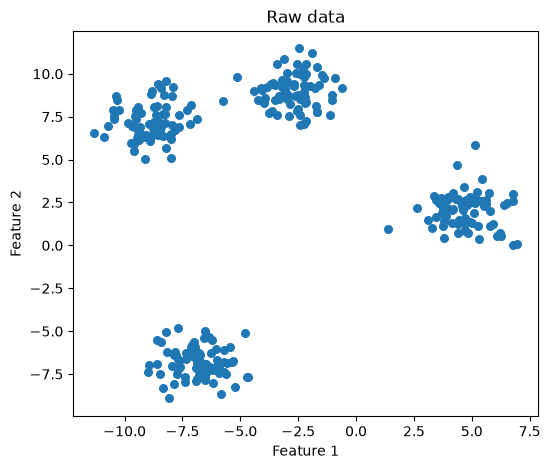

In [4]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=30)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Raw data")
plt.show()

Step 3: Scale the data
K-Means uses distances, so features should be on the same scale. We use StandardScaler to give each feature a mean of 0 and a standard deviation of 1.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Mean after scaling:", X_scaled.mean(axis=0).round(2))
print("Std after scaling:", X_scaled.std(axis=0).round(2))

Mean after scaling: [ 0. -0.]
Std after scaling: [1. 1.]


Step 4: Elbow Method
We run K-Means for K = 1 to 10 and store the inertia of each model.

In [6]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

for k, i in zip(k_values, inertias):
    print("K =", k, " Inertia =", round(i, 2))

K = 1  Inertia = 600.0
K = 2  Inertia = 315.49
K = 3  Inertia = 71.69
K = 4  Inertia = 17.47
K = 5  Inertia = 15.64
K = 6  Inertia = 13.85
K = 7  Inertia = 12.18
K = 8  Inertia = 10.84
K = 9  Inertia = 9.86
K = 10  Inertia = 8.83


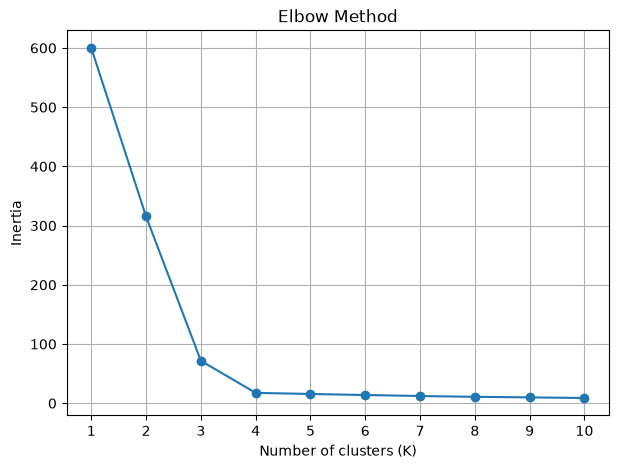

In [7]:
plt.figure(figsize=(7, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Observation: The inertia drops quickly up to K = 4 and after that the curve becomes almost flat. So the elbow is at K = 4.

Step 5: Silhouette Score
The silhouette score needs at least 2 clusters, so we check K = 2 to 10.

In [8]:
sil_scores = []
sil_k = range(2, 11)

for k in sil_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print("K =", k, " Silhouette Score =", round(score, 4))

K = 2  Silhouette Score = 0.5577
K = 3  Silhouette Score = 0.7436
K = 4  Silhouette Score = 0.7975
K = 5  Silhouette Score = 0.6736
K = 6  Silhouette Score = 0.5513
K = 7  Silhouette Score = 0.4412
K = 8  Silhouette Score = 0.3382
K = 9  Silhouette Score = 0.3478
K = 10  Silhouette Score = 0.3663


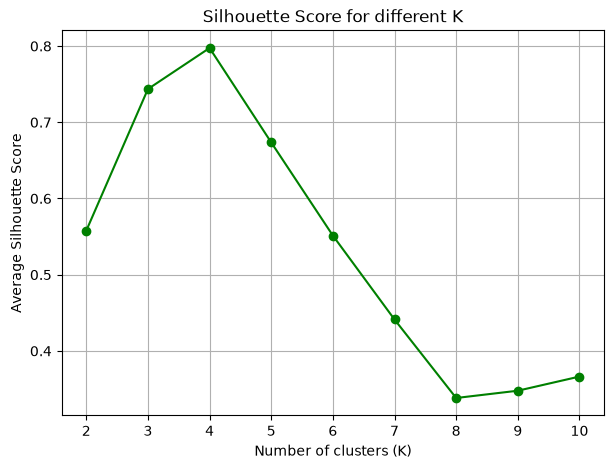

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(list(sil_k), sil_scores, marker="o", color="green")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Score for different K")
plt.xticks(list(sil_k))
plt.grid(True)
plt.show()

In [10]:
best_k = list(sil_k)[int(np.argmax(sil_scores))]
print("Best K according to silhouette score:", best_k)
print("Highest silhouette score:", round(max(sil_scores), 4))

Best K according to silhouette score: 4
Highest silhouette score: 0.7975


Observation: The silhouette score is highest at the K value printed above. Both the Elbow Method and the Silhouette Score agree on the same K, so we use it for the final model.

Step 6: Final K-Means model with the optimal K

In [11]:
final_km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
labels = final_km.fit_predict(X_scaled)

df["Cluster"] = labels
print("Final silhouette score:", round(silhouette_score(X_scaled, labels), 4))
print()
print("Number of points in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Final silhouette score: 0.7975

Number of points in each cluster:
Cluster
0    76
1    75
2    75
3    74
Name: count, dtype: int64


Now we plot the clusters along with their centroids.

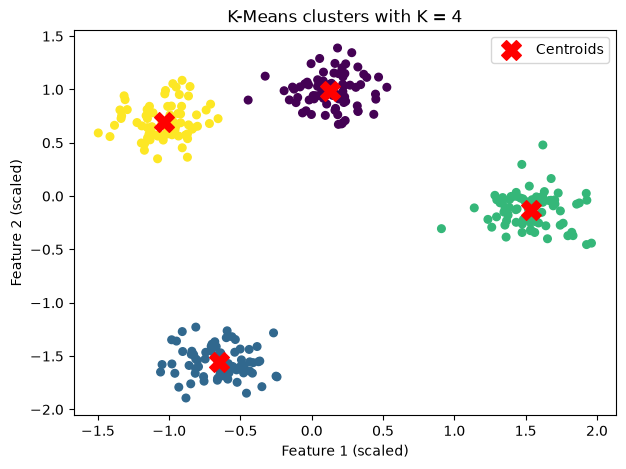

In [12]:
centroids = final_km.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="viridis", s=30)
plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("K-Means clusters with K = " + str(best_k))
plt.legend()
plt.show()

Cluster centers in the original scale of the data:

In [13]:
original_centers = scaler.inverse_transform(centroids)
pd.DataFrame(original_centers, columns=["Feature 1", "Feature 2"])

,Feature 1,Feature 2
0,-2.709811,8.971433
1,-6.832352,-6.830457
2,4.718205,2.041797
3,-8.873572,7.174583


Step 7: Compare with wrong values of K (optional)
This shows what happens if K is too small or too large.

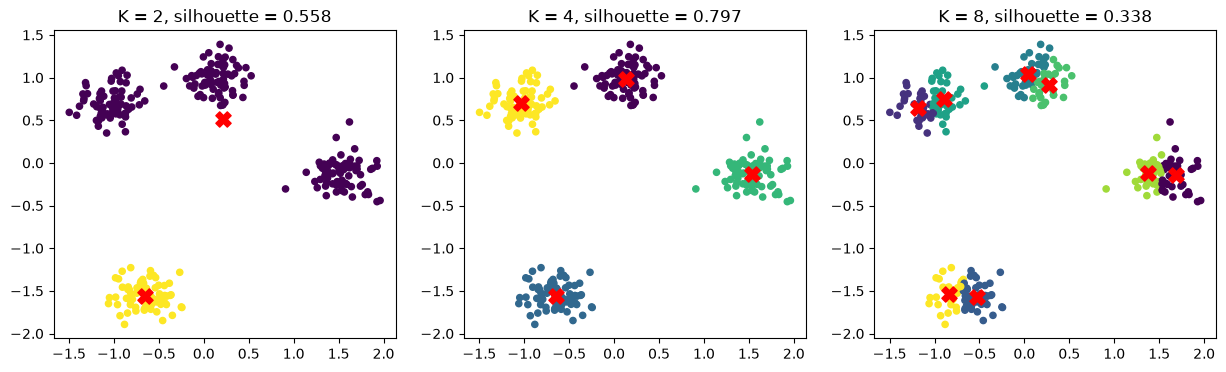

In [14]:
test_ks = [2, best_k, 8]
plt.figure(figsize=(15, 4))

for i, k in enumerate(test_ks):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    plt.subplot(1, 3, i + 1)
    plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=lab, cmap="viridis", s=20)
    plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c="red", marker="X", s=120)
    plt.title("K = " + str(k) + ", silhouette = " + str(round(silhouette_score(X_scaled, lab), 3)))

plt.show()

Conclusion:
- K-Means was applied on a 2 feature dataset after scaling the data.
- The Elbow Method showed a clear bend at K = 4.
- The Silhouette Score was highest for the same K.
- Using the optimal K, the data was divided into well separated clusters and the centroids were plotted.
- Choosing a K that is too small merges different groups, and a K that is too large splits one group into parts, which lowers the silhouette score.